# Curso de manejo

Antes de la simulación, los coches juegan en parejas el juego de dos roles de la Étoile (A circula por la glorieta, B se integra) y aprenden con **juego ficticio**: cada uno cuenta lo que ha visto hacer a sus rivales y elige la acción de mayor pago esperado.

Al final se guardan los conteos de cada conductor en `drivers.json`, que carga `main.py`. Sin ese archivo, los conductores salen novatos.

In [2]:
import json
import sys
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")   # importa config, agents y environment desde la raíz del repo

from agents.game_theory import ROLE_A, ROLE_B, go_threshold
from config import DRIVERS_FILE, N_CARS, SEED, WARMUP_ROUNDS
from environment.city_model import CityModel

COORDINATION_TARGET = 0.95   # M5: proporción mínima de encuentros coordinados al final del curso
COORDINATION_WINDOW = 10     # últimas rondas en que se mide
BELIEF_BAND = (10, 90)       # percentiles de la banda de creencias en la gráfica

## Curso

Cada ronda se barajan los coches, se forman parejas, se sortean los roles y juegan.

In [3]:
model = CityModel({"n_cars": N_CARS, "seed": SEED})
model.sim_setup()
log = model.warmup(WARMUP_ROUNDS)

for r in (1, 10, 20, 30, WARMUP_ROUNDS):
    tally = log.outcomes[r - 1]
    print(f"ronda {r:2d}: " + " · ".join(f"{k} {tally[k] / tally.total():4.0%}" for k in ("CC", "A", "B", "DD")))

tail = log.outcomes[-COORDINATION_WINDOW:]
coordinated = sum(t["A"] + t["B"] for t in tail) / sum(t.total() for t in tail)
print(f"coordinados en las últimas {COORDINATION_WINDOW} rondas: {coordinated:.0%}")
assert coordinated >= COORDINATION_TARGET, "M5: al final del curso se coordina menos del 95 % de los encuentros"

ronda  1: CC 100% · A   0% · B   0% · DD   0%
ronda 10: CC  54% · A  46% · B   0% · DD   0%
ronda 20: CC   0% · A 100% · B   0% · DD   0%
ronda 30: CC   2% · A  98% · B   0% · DD   0%
ronda 60: CC   0% · A 100% · B   0% · DD   0%
coordinados en las últimas 10 rondas: 100%


## Acciones y creencias

Arriba, la proporción que elige seguir (D) en cada rol; abajo, la creencia promedio de que el rival sigue, con la banda del 10 al 90 %. Las acciones se grafican tal cual: en un encuentro D/D, A y B cuentan como D, y esas rondas se marcan en rojo.

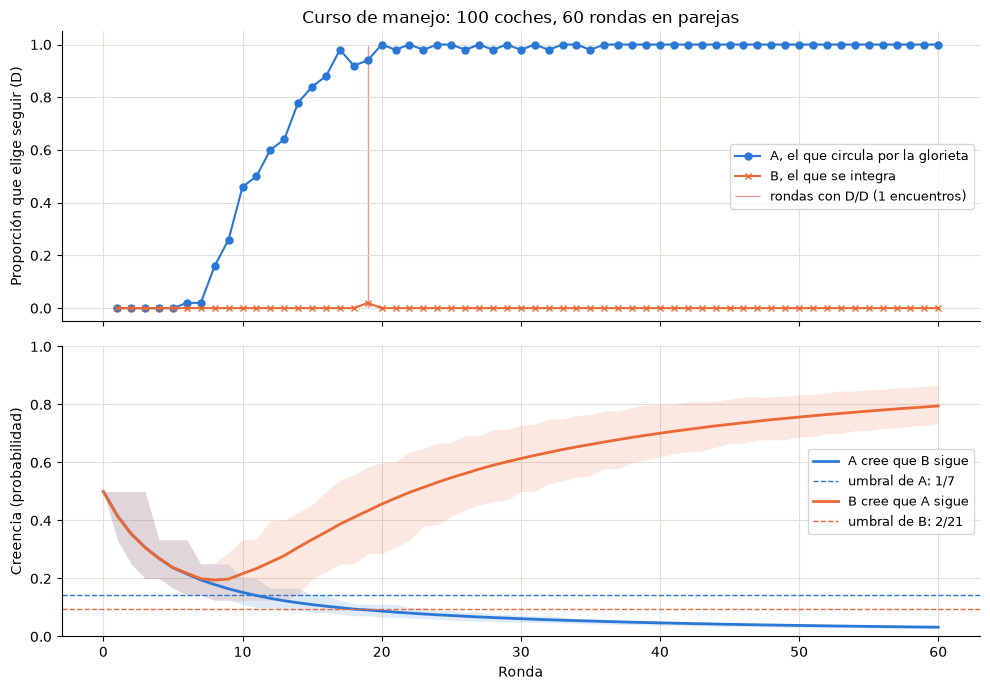

In [4]:
ROLE_COLORS = ("#2a78d6", "#eb6834")        # A, B
DD_COLOR = "#d03b3b"
ROLE_LABELS = ("A, el que circula por la glorieta", "B, el que se integra")
BELIEF_LABELS = ("A cree que B sigue", "B cree que A sigue")
THRESHOLD_LABELS = tuple(f"umbral de {name}: {Fraction(go_threshold(role)).limit_denominator(1000)}"
                         for role, name in ((ROLE_A, "A"), (ROLE_B, "B")))

rounds = np.arange(1, WARMUP_ROUNDS + 1)
steps = np.arange(WARMUP_ROUNDS + 1)
share_go = np.nanmean(log.actions, axis=1)              # (rondas, 2): proporción que siguió
mean_belief = log.beliefs.mean(axis=1)
low, high = np.percentile(log.beliefs, BELIEF_BAND, axis=1)
dd_rounds = [r for r, tally in zip(rounds, log.outcomes) if tally["DD"]]
n_dd = sum(t["DD"] for t in log.outcomes)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for role, marker in ((ROLE_A, "o"), (ROLE_B, "x")):
    top.plot(rounds, share_go[:, role], color=ROLE_COLORS[role], marker=marker, ms=5, lw=1.5, label=ROLE_LABELS[role])
    bottom.plot(steps, mean_belief[:, role], color=ROLE_COLORS[role], lw=2, label=BELIEF_LABELS[role])
    bottom.fill_between(steps, low[:, role], high[:, role], color=ROLE_COLORS[role], alpha=0.15, lw=0)
    bottom.axhline(go_threshold(role), color=ROLE_COLORS[role], lw=1, ls="--", label=THRESHOLD_LABELS[role])
top.vlines(dd_rounds, 0, 1, color=DD_COLOR, lw=1, alpha=0.5, zorder=0,
           label=f"rondas con D/D ({n_dd} encuentros)" if n_dd else "rondas con D/D: ninguna")
top.set_ylim(-0.05, 1.05)
top.set_ylabel("Proporción que elige seguir (D)")
top.set_title(f"Curso de manejo: {N_CARS} coches, {WARMUP_ROUNDS} rondas en parejas")
bottom.set_ylim(0, 1)
bottom.set_xlabel("Ronda")
bottom.set_ylabel("Creencia (probabilidad)")
for ax in (top, bottom):
    ax.grid(color="#e1e0d9", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
plt.show()

## Guardar los datos

In [5]:
with open(DRIVERS_FILE, "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "n_cars": N_CARS, "rounds": WARMUP_ROUNDS, "counts": [car.counts.tolist() for car in model.cars]}, f)